# Chapter 56: Comparative Advantage, Factor Endowments, and Distribution

This notebook reruns four worked examples from the chapter: Stolper-Samuelson magnification, the Rybczynski output effect, winners and losers with specific factors, and factor-price equalization. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def plus(value, digits=2, comma=True):
    """Number with an explicit sign for changes: '+0.42', '-0.20', '0.00'."""
    text = num(value, digits, comma)
    return text if text.startswith("-") or float(text.replace(",", "")) == 0 else f"+{text}"


def solve_unit_costs(aLC, aKC, aLF, aKF, pC, pF):
    """Factor prices from zero-profit unit-cost equations aLC w + aKC r = pC, aLF w + aKF r = pF.

    stolper-samuelson-theorem (chapter 56): (2, 1, 1, 2) at prices (30, 30) gives (w, r) = (10, 10);
    at (36, 30) gives (14, 8). factor-price-equalization-theorem: (24, 39) -> (3, 18); (36, 33) -> (13, 10);
    (30, 36) -> (8, 14). Returns w, r, det and positive (both factor prices above zero).
    """
    det = aLC * aKF - aKC * aLF
    w = (pC * aKF - aKC * pF) / det
    r = (aLC * pF - aLF * pC) / det
    return {"w": w, "r": r, "det": det, "positive": w > 0 and r > 0}


def solve_full_employment(aLX, aKX, aLY, aKY, L, K):
    """Outputs that fully employ both factors: aLX X + aLY Y = L, aKX X + aKY Y = K.

    rybczynski-theorem (chapter 56): cloth (2L, 1K), machines (1L, 2K); L = K = 300 gives (100, 100);
    L = 360 gives (140, 80). ``diversified`` is False when either solved output is negative, meaning the
    endowment lies outside the diversification cone and the economy specializes.
    """
    det = aLX * aKY - aLY * aKX
    X = (L * aKY - aLY * K) / det
    Y = (aLX * K - aKX * L) / det
    return {"X": X, "Y": Y, "diversified": X >= 0 and Y >= 0}


def specific_factors(pX, pM, L, aX=10, aM=10):
    """Specific-factors model with Q_j = a_j sqrt(L_j) and mobile labor L.

    specific-factors-distribution-effect (chapter 56): pX = pM = 1, L = 100: L_X = 50, w = 0.7071,
    rents 35.36 each. pX = 1.5: L_X = 69.23, L_M = 30.77, w = 0.9014, R_X = 62.40, R_M = 27.74.
    Wage equality pX aX / (2 sqrt L_X) = pM aM / (2 sqrt L_M) gives L_X / L_M = (pX aX / (pM aM))^2.
    Rent R_j = p_j Q_j - w L_j = p_j a_j sqrt(L_j) / 2.
    """
    ratio = (pX * aX / (pM * aM)) ** 2
    LM = L / (1.0 + ratio)
    LX = L - LM
    w = pM * aM / (2.0 * math.sqrt(LM))
    return {"LX": LX, "LM": LM, "w": w, "RX": pX * aX * math.sqrt(LX) / 2.0, "RM": pM * aM * math.sqrt(LM) / 2.0,
            "QX": aX * math.sqrt(LX), "QM": aM * math.sqrt(LM)}


plt.rcParams.update(HOUSE_RC)


trade = SimpleNamespace(solve_unit_costs=solve_unit_costs, solve_full_employment=solve_full_employment, specific_factors=specific_factors)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'stolper-samuelson-theorem': {'a': (2, 1, 1, 2),
                               'p0': (30, 30),
                               'p1': (36, 30),
                               'w0': 10,
                               'r0': 10,
                               'w1': 14,
                               'r1': 8,
                               'wage_change_pct': 40,
                               'w_cloth': 0.389,
                               'w_food': 0.467,
                               'r_cloth': 0.222,
                               'r_food': 0.267},
 'rybczynski-theorem': {'a': (2, 1, 1, 2),
                        'L0': 300,
                        'K0': 300,
                        'L1': 360,
                        'X0': 100,
                        'Y0': 100,
                        'X1': 140,
                        'Y1': 80,
                        'cloth_change_pct': 40},
 'specific-factors-distribution-effect': {'L': 100,
                                          'pM': 1,
                                          'pX0': 1,
                                          'pX1': 1.5,
                                          'w0': 0.7071,
                                          'R0': 35.36,
                                          'LX': 69.23,
                                          'LM': 30.77,
                                          'w1': 0.9014,
                                          'wage_change_pct': 27.5,
                                          'w_in_X': 0.6009,
                                          'w_in_X_change_pct': -15.0,
                                          'RX': 62.4,
                                          'RX_change_pct': 76.5,
                                          'RM': 27.74,
                                          'RM_change_pct': -21.6},
 'factor-price-equalization-theorem': {'a': (2, 1, 1, 2),
                                       'A_autarky': (24, 39),
                                       'B_autarky': (36, 33),
                                       'trade': (30, 36),
                                       'A_wr': (3, 18),
                                       'B_wr': (13, 10),
                                       'trade_wr': (8, 14)},
 'constructed': {'stolper-samuelson-theorem': {'pC': [33, 39], 'pF': [27, 33]},
                 'rybczynski-theorem': {'L': [330, 390], 'K': [270, 330]},
                 'specific-factors-distribution-effect': {'pX': [1.25, 2.0]},
                 'factor-price-equalization-theorem': {'pM': [33, 39]}}}


def pct_change(new, old):
    """Percent change from old to new."""
    return 100.0 * (new / old - 1.0)


def direction(new, old, up="rises", down="falls", flat="is unchanged"):
    """Verb for a change, judged at 3 decimals."""
    if abs(new - old) < 5e-4:
        return flat
    return up if new > old else down


def moves(new, old, pct):
    """'rises 40.00 percent', 'falls 20.00 percent' or 'is unchanged', judged at 3 decimals."""
    verb = direction(new, old)
    return verb if verb == "is unchanged" else f"{verb} {num(abs(pct))} percent"


def real_verdict(who, a, b, thing):
    """Real-reward verdict from purchasing power in the two goods against the baseline 1/3."""
    base = 1 / 3
    if a > base + 5e-4 and b > base + 5e-4:
        return f"{who} gains in terms of both goods"
    if a < base - 5e-4 and b < base - 5e-4:
        return f"{who} loses in terms of both goods"
    if abs(a - base) <= 5e-4 and abs(b - base) <= 5e-4:
        return f"{who}'s real {thing} is unchanged in terms of both goods"
    return f"{who}'s real {thing} moves in opposite directions across the two goods"


def cost_lines(ax, pC, pF, col_c="navy", col_f="gold", style="solid", text=True):
    """Unit-cost lines 2w + r = pC and w + 2r = pF in the (w, r) plane."""
    ws = np.linspace(0, 25, 200)
    ax.plot(ws, pC - 2 * ws, color=PALETTE[col_c], linestyle=style, linewidth=2 if style == "solid" else 1.3)
    ax.plot(ws, (pF - ws) / 2, color=PALETTE[col_f], linestyle=style, linewidth=2 if style == "solid" else 1.3)


def stolper_picture(pc=36, pf=30):
    s0 = trade.solve_unit_costs(2, 1, 1, 2, 30, 30)
    s1 = trade.solve_unit_costs(2, 1, 1, 2, pc, pf)
    w0, r0, w, r = s0["w"], s0["r"], s1["w"], s1["r"]
    fig, ax = new_figure()
    cost_lines(ax, 30, 30, "grey", "grey", style="dashed")
    cost_lines(ax, pc, pf)
    label(ax, 2.0, pc - 4.0, f"cloth: 2w + r = {pc}", col="navy", dx=6, dy=0, va="center")
    label(ax, 20.5, (pf - 20.5) / 2, f"food: w + 2r = {pf}", col="gold", dx=0, dy=8, ha="center")
    mark(ax, w0, r0, "baseline (10, 10)", col="grey", dx=-8, dy=-8, ha="right", va="top")
    mark(ax, w, r, f"new ({num(w)}, {num(r)})", col="terracotta", dx=8, dy=8)
    ax.set_xlim(0, 25)
    ax.set_ylim(0, 42)
    ax.set_xlabel("Wage w")
    ax.set_ylabel("Capital rental r")
    dw, dpc, dpf = pct_change(w, w0), pct_change(pc, 30), pct_change(pf, 30)
    metrics = {"Wage w": num(w), "Rental r": num(r), "Wage change": f"{plus(dw)}%", "Cloth price change": f"{plus(dpc)}%",
               "Food price change": f"{plus(dpf)}%", "Real wage in cloth w/pC": num(w / pc, 3),
               "Real wage in food w/pF": num(w / pf, 3), "Real rental in cloth r/pC": num(r / pc, 3),
               "Real rental in food r/pF": num(r / pf, 3)}
    labor = real_verdict("Labor", w / pc, w / pf, "wage")
    capital = real_verdict("capital", r / pc, r / pf, "rental")
    interp = (f"Subtracting 2 x (w + 2r = {pf}) from 2w + r = {pc} gives -3r = {pc} - {2 * pf}, so r = "
              f"{num(r)} and w = ({pc} - {num(r)}) / 2 = {num(w)}. The wage {moves(w, w0, dw)} "
              f"against a cloth price change of {num(dpc)} percent and a food price change of "
              f"{num(dpf)} percent. Starting from 10 / 30 = 0.333 of either good, the wage buys {num(w)} / {pc} = "
              f"{num(w / pc, 3)} cloth and {num(w)} / {pf} = {num(w / pf, 3)} food; the rental buys "
              f"{num(r / pc, 3)} cloth and {num(r / pf, 3)} food. {labor}, and {capital}.")
    steps = [f"2w + r = {pc} and w + 2r = {pf}",
             f"3r = 2 x {pf} - {pc} = {num(2 * pf - pc, 0)}, so r = {num(r)}",
             f"w = ({pc} - {num(r)}) / 2 = {num(w)}",
             f"Wage change = ({num(w)} - 10) / 10 = {plus(dw)}%",
             f"Real wage: {num(w)} / {pc} = {num(w / pc, 3)} cloth, {num(w)} / {pf} = {num(w / pf, 3)} food"]
    alt = (f"Unit-cost lines for cloth and food in the wage-rental plane. The baseline lines cross at (10, 10); at "
           f"prices {pc} and {pf} they cross at w = {num(w)}, r = {num(r)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def rybczynski_picture(labor=360, capital=300):
    base = trade.solve_full_employment(2, 1, 1, 2, 300, 300)
    s = trade.solve_full_employment(2, 1, 1, 2, labor, capital)
    X, Y = s["X"], s["Y"]
    fig, ax = new_figure()
    xs = np.linspace(0, 220, 200)
    ax.plot(xs, 300 - 2 * xs, color=PALETTE["grey"], linestyle="dashed", linewidth=1.3)
    ax.plot(xs, (300 - xs) / 2, color=PALETTE["grey"], linestyle="dashed", linewidth=1.3)
    ax.plot(xs, labor - 2 * xs, color=PALETTE["navy"], linewidth=2)
    ax.plot(xs, (capital - xs) / 2, color=PALETTE["gold"], linewidth=2)
    label(ax, 25, labor - 50, f"labor: 2X + Y = {labor}", col="navy", dx=6, dy=0, va="center")
    label(ax, 216, (capital - 216) / 2, f"capital: X + 2Y = {capital}", col="gold", dx=0, dy=-8, ha="right", va="top")
    mark(ax, 100, 100, "baseline (100, 100)", col="grey", dx=-8, dy=8, ha="right")
    if s["diversified"]:
        far = X > 150
        mark(ax, X, Y, f"new ({num(X)}, {num(Y)})", col="terracotta", dx=-8 if far else 8, dy=8,
             ha="right" if far else "left")
    ax.set_xlim(0, 220)
    ax.set_ylim(0, 420)
    ax.set_xlabel("Cloth output X")
    ax.set_ylabel("Machine output Y")
    dL, dK = pct_change(labor, 300), pct_change(capital, 300)
    dX, dY = pct_change(X, 100), pct_change(Y, 100)
    metrics = {"Cloth X": num(X), "Machines Y": num(Y), "Cloth change": f"{plus(dX)}%", "Machine change": f"{plus(dY)}%",
               "Labor change": f"{plus(dL)}%", "Capital change": f"{plus(dK)}%",
               "Both goods produced": "yes" if s["diversified"] else "no, the economy specializes"}
    if abs(dL - dK) < 5e-4:
        magnify = ("Both endowments change by the same percentage, so both outputs change by that percentage too: "
                   "there is no magnification.")
    else:
        grow = "labor" if dL > dK else "capital"
        big, small = ("Cloth", "machine") if dL > dK else ("Machine", "cloth")
        hi, lo = (dX, dY) if dL > dK else (dY, dX)
        magnify = (f"Labor grows relative to capital" if dL > dK else "Capital grows relative to labor") + (
            f", so {big.lower()} output, which uses {grow} intensively, changes by more than either endowment "
            f"({plus(hi)} percent) and {small} output by less than either ({plus(lo)} percent): the magnification "
            f"effect.")
    interp = (f"From 2X + Y = {labor} and X + 2Y = {capital}: 3X = 2 x {labor} - {capital} = {num(3 * X, 0)}, so "
              f"X = {num(X)}, and Y = ({capital} - {num(X)}) / 2 = {num(Y)}. Cloth output {moves(X, 100, dX)} "
              f"and machine output {moves(Y, 100, dY)}, while labor changed {plus(dL)} percent and capital "
              f"{plus(dK)} percent. {magnify}")
    steps = [f"2X + Y = {labor} and X + 2Y = {capital}",
             f"3X = 2 x {labor} - {capital} = {num(3 * X, 0)}, so X = {num(X)}",
             f"Y = ({capital} - {num(X)}) / 2 = {num(Y)}",
             f"Cloth change = ({num(X)} - 100) / 100 = {plus(dX)}%",
             f"Machine change = ({num(Y)} - 100) / 100 = {plus(dY)}%"]
    alt = (f"Full-employment lines for labor and capital in output space. The baseline lines cross at (100, 100); "
           f"with labor {labor} and capital {capital} they cross at X = {num(X)}, Y = {num(Y)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def specific_picture(px=1.5):
    b0 = trade.specific_factors(1.0, 1.0, 100)
    s = trade.specific_factors(px, 1.0, 100)
    LX, LM, w = s["LX"], s["LM"], s["w"]
    w0 = b0["w"]
    fig, ax = new_figure()
    xs = np.linspace(2, 98, 300)
    vx = px * 5 / np.sqrt(xs)
    vm = 5 / np.sqrt(100 - xs)
    ax.plot(xs, vx, color=PALETTE["navy"], linewidth=2)
    ax.plot(xs, vm, color=PALETTE["gold"], linewidth=2)
    left = xs <= LX
    ax.fill_between(xs[left], w, vx[left], color=PALETTE["navy"], alpha=0.15)
    ax.fill_between(xs[~left], w, vm[~left], color=PALETTE["gold"], alpha=0.18)
    ax.axhline(w, color=PALETTE["grey"], linestyle="dashed", linewidth=1.2)
    label(ax, 4, 2.6, f"export sector X: {num(px, 2)} x 5 / sqrt(L_X)", col="navy", dx=0, dy=0)
    label(ax, 96, 2.25, "import sector M: 5 / sqrt(L_M)", col="gold", dx=0, dy=0, ha="right")
    mark(ax, LX, w, f"w = {num(w, 4)} at L_X = {num(LX)}", col="terracotta", dx=0, dy=-14, ha="center", va="top")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 3.0)
    ax.set_xlabel("Workers in X (from left); workers in M = 100 - L_X")
    ax.set_ylabel("Value of marginal product, wage")
    ratio = px ** 2
    dw = pct_change(w, w0)
    dwx = pct_change(w / px, w0)
    drx, drm = pct_change(s["RX"], b0["RX"]), pct_change(s["RM"], b0["RM"])
    metrics = {"L_X": num(LX), "L_M": num(LM), "Wage w": num(w, 4), "Wage change (in M)": f"{plus(dw, 1)}%",
               "Real wage in X": f"{num(w / px, 4)} ({plus(dwx, 1)}%)", "Rent R_X": f"{num(s['RX'])} ({plus(drx, 1)}%)",
               "Rent R_M": f"{num(s['RM'])} ({plus(drm, 1)}%)"}
    if abs(px - 1.0) < 1e-12:
        verdict = "With equal prices this is the baseline: each sector holds 50 workers and each rent is 35.36."
    else:
        verdict = (f"Workers gain in terms of M but lose in terms of X; the X-specific factor clearly gains and the "
                   f"M-specific factor clearly loses.")
    interp = (f"Wage equality gives L_X = {num(px, 2)}^2 L_M = {num(ratio, 4)} L_M, so L_M = 100 / {num(1 + ratio, 4)} "
              f"= {num(LM)} and L_X = {num(LX)}. The wage is 5 / sqrt({num(LM)}) = {num(w, 4)}, "
              f"{plus(dw, 1)} percent from 0.7071; measured in X it is {num(w, 4)} / {num(px, 2)} = {num(w / px, 4)}. "
              f"R_X = {num(px, 2)} x 5 x sqrt({num(LX)}) = {num(s['RX'])} and R_M = 5 x sqrt({num(LM)}) = "
              f"{num(s['RM'])}, against 35.36 each at the start. {verdict}")
    steps = [f"L_X / L_M = {num(px, 2)} x {num(px, 2)} = {num(ratio, 4)}",
             f"L_M = 100 / {num(1 + ratio, 4)} = {num(LM)}; L_X = 100 - {num(LM)} = {num(LX)}",
             f"w = 5 / sqrt({num(LM)}) = {num(w, 4)}",
             f"Wage in X = {num(w, 4)} / {num(px, 2)} = {num(w / px, 4)}",
             f"R_X = {num(px, 2)} x 5 x sqrt({num(LX)}) = {num(s['RX'])}; R_M = 5 x sqrt({num(LM)}) = {num(s['RM'])}"]
    alt = (f"Two value-of-marginal-product curves across 100 workers. They cross at L_X = {num(LX)} with wage "
           f"{num(w, 4)}; the shaded areas above the wage are the two sector-specific rents, {num(s['RX'])} and "
           f"{num(s['RM'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def fpe_picture(regime="free trade", pm=36):
    a = trade.solve_unit_costs(2, 1, 1, 2, 24, 39)
    b = trade.solve_unit_costs(2, 1, 1, 2, 36, 33)
    t = trade.solve_unit_costs(2, 1, 1, 2, 30, pm)
    fig, ax = new_figure()
    mark(ax, a["w"], a["r"], f"A autarky ({num(a['w'], 0)}, {num(a['r'], 0)})", col="navy", dx=8, dy=6)
    mark(ax, b["w"], b["r"], f"B autarky ({num(b['w'], 0)}, {num(b['r'], 0)})", col="gold", dx=8, dy=-6, va="top")
    trade_on = regime == "free trade"
    if trade_on:
        cost_lines(ax, 30, pm, "grey", "grey", style="dashed")
        for p, col in ((a, "navy"), (b, "gold")):
            ax.annotate("", (t["w"], t["r"]), (p["w"], p["r"]),
                        arrowprops={"arrowstyle": "->", "color": PALETTE[col], "lw": 1.6})
        mark(ax, t["w"], t["r"], f"both with trade ({num(t['w'])}, {num(t['r'])})", col="terracotta", dx=8, dy=8)
    ax.set_xlim(0, 20)
    ax.set_ylim(0, 24)
    ax.set_xlabel("Wage w")
    ax.set_ylabel("Capital rental r")
    if trade_on:
        metrics = {"Prices in force": f"pC = 30, pM = {pm} in both countries", "Common wage": num(t["w"]),
                   "Common rental": num(t["r"]), "A's wage": f"3 to {num(t['w'])}", "B's wage": f"13 to {num(t['w'])}"}
        interp = (f"With common prices pC = 30 and pM = {pm}, both countries solve 2w + r = 30 and w + 2r = {pm}. "
                  f"Then 3r = 2 x {pm} - 30 = {num(3 * t['r'], 0)}, so r = {num(t['r'])}, and w = {pm} - 2 x "
                  f"{num(t['r'])} = {num(t['w'])}. A's wage {direction(t['w'], 3)} from 3 and its rental "
                  f"{direction(t['r'], 18)} from 18; B's wage {direction(t['w'], 13)} from 13 and its rental "
                  f"{direction(t['r'], 10)} from 10. Factor prices are equal although no factor crosses the border.")
        steps = [f"2w + r = 30 and w + 2r = {pm}",
                 f"3r = 2 x {pm} - 30 = {num(3 * t['r'], 0)}, so r = {num(t['r'])}",
                 f"w = {pm} - 2 x {num(t['r'])} = {num(t['w'])}",
                 f"A: (3, 18) to ({num(t['w'])}, {num(t['r'])}); B: (13, 10) to ({num(t['w'])}, {num(t['r'])})"]
        alt = (f"Wage-rental plane with A's autarky point (3, 18) and B's (13, 10); arrows lead to the common "
               f"free-trade point ({num(t['w'])}, {num(t['r'])}).")
    else:
        metrics = {"Prices in force": "each country's own autarky prices", "A's wage and rental": "3 and 18",
                   "B's wage and rental": "13 and 10", "Common wage": "none: each country has its own"}
        interp = ("In autarky A solves 2w + r = 24 and w + 2r = 39: 3r = 2 x 39 - 24 = 54, so r = 18 and w = "
                  "39 - 2 x 18 = 3. B solves 2w + r = 36 and w + 2r = 33: 3r = 2 x 33 - 36 = 30, so r = 10 and "
                  "w = 33 - 2 x 10 = 13. Labor is cheap in A and capital cheap in B. The world machinery price "
                  "plays no role until trade opens.")
        steps = ["A: 3r = 2 x 39 - 24 = 54, r = 18, w = 39 - 36 = 3",
                 "B: 3r = 2 x 33 - 36 = 30, r = 10, w = 33 - 20 = 13"]
        alt = "Wage-rental plane with A's autarky point (3, 18) and B's autarky point (13, 10)."
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Stolper-Samuelson theorem: a price rise magnified in wages

Cloth uses 2 labor and 1 capital, food 1 labor and 2 capital. Prices equal unit costs. After cloth's price rises from 30 to 36:

$$2w+r=36,\qquad w+2r=30.$$

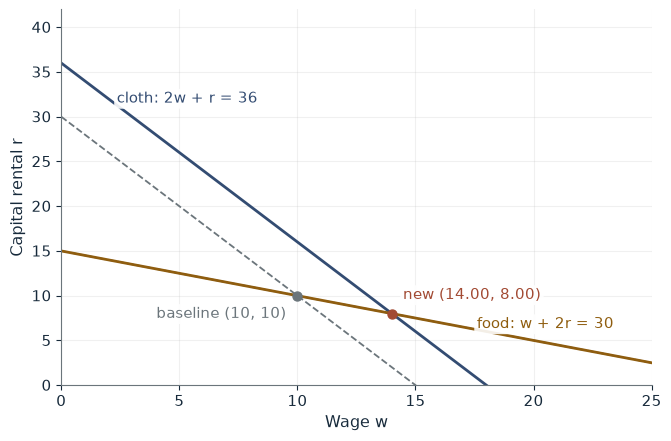

Wage w                     14.00
Rental r                   8.00
Wage change                +40.00%
Cloth price change         +20.00%
Food price change          0.00%
Real wage in cloth w/pC    0.389
Real wage in food w/pF     0.467
Real rental in cloth r/pC  0.222
Real rental in food r/pF   0.267

Worked steps:
  1. 2w + r = 36 and w + 2r = 30
  2. 3r = 2 x 30 - 36 = 24, so r = 8.00
  3. w = (36 - 8.00) / 2 = 14.00
  4. Wage change = (14.00 - 10) / 10 = +40.00%
  5. Real wage: 14.00 / 36 = 0.389 cloth, 14.00 / 30 = 0.467 food

Subtracting 2 x (w + 2r = 30) from 2w + r = 36 gives -3r = 36 - 60, so r = 8.00 and w = (36 - 8.00) / 2 = 14.00. The wage rises 40.00 percent against a cloth price change of 20.00 percent and a food price change of 0.00 percent. Starting from 10 / 30 = 0.333 of either good, the wage buys 14.00 / 36 = 0.389 cloth and 14.00 / 30 = 0.467 food; the rental buys 0.222 cloth and 0.267 food. Labor gains in terms of both goods, and capital loses in terms of both goods.


In [2]:
show(stolper_picture(pc=36, pf=30))

Change one input, `pc`, and hold the others at the book's values:

In [3]:
sweep(stolper_picture, 'pc', [30, 33, 36, 39], {'pf': 30}, ['Wage w', 'Rental r', 'Wage change'])

pc | Wage w | Rental r | Wage change
30 | 10.00 | 10.00 | 0.00%
33 | 12.00 | 9.00 | +20.00%
36 | 14.00 | 8.00 | +40.00%
39 | 16.00 | 7.00 | +60.00%


The wage rises 40 percent, from 10 to 14, twice the 20 percent cloth price rise, and the rental falls from 10 to 8: labor gains in terms of both goods and capital loses.

## 2. Rybczynski theorem: more workers, fewer machines

Cloth X uses 2L + 1K, machines Y use 1L + 2K. With L = 360 and K = 300:

$$2X+Y=360,\qquad X+2Y=300.$$

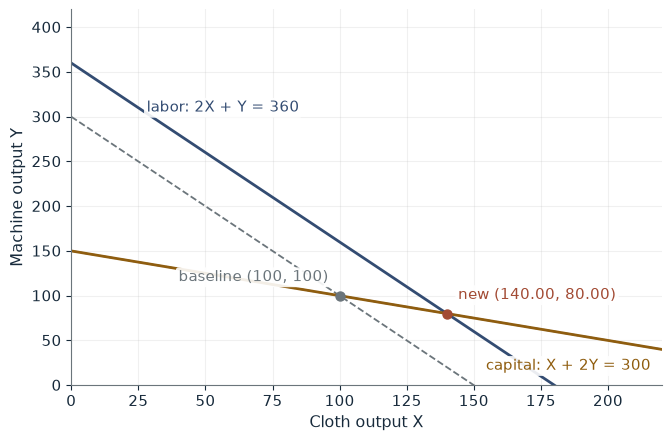

Cloth X              140.00
Machines Y           80.00
Cloth change         +40.00%
Machine change       -20.00%
Labor change         +20.00%
Capital change       0.00%
Both goods produced  yes

Worked steps:
  1. 2X + Y = 360 and X + 2Y = 300
  2. 3X = 2 x 360 - 300 = 420, so X = 140.00
  3. Y = (300 - 140.00) / 2 = 80.00
  4. Cloth change = (140.00 - 100) / 100 = +40.00%
  5. Machine change = (80.00 - 100) / 100 = -20.00%

From 2X + Y = 360 and X + 2Y = 300: 3X = 2 x 360 - 300 = 420, so X = 140.00, and Y = (300 - 140.00) / 2 = 80.00. Cloth output rises 40.00 percent and machine output falls 20.00 percent, while labor changed +20.00 percent and capital 0.00 percent. Labor grows relative to capital, so cloth output, which uses labor intensively, changes by more than either endowment (+40.00 percent) and machine output by less than either (-20.00 percent): the magnification effect.


In [4]:
show(rybczynski_picture(labor=360, capital=300))

Change one input, `labor`, and hold the others at the book's values:

In [5]:
sweep(rybczynski_picture, 'labor', [300, 330, 360, 390], {'capital': 300}, ['Cloth X', 'Machines Y', 'Cloth change'])

labor | Cloth X | Machines Y | Cloth change
300 | 100.00 | 100.00 | 0.00%
330 | 120.00 | 90.00 | +20.00%
360 | 140.00 | 80.00 | +40.00%
390 | 160.00 | 70.00 | +60.00%


A 20 percent rise in labor raises cloth 40 percent, to 140, and cuts machines 20 percent, to 80.

## 3. Specific-factors distribution effect

100 mobile workers, $Q_X=10\sqrt{L_X}$ and $Q_M=10\sqrt{L_M}$, $p_M=1$. When $p_X$ rises to 1.5:

$$\frac{7.5}{\sqrt{L_X}}=\frac{5}{\sqrt{L_M}},\qquad L_X+L_M=100.$$

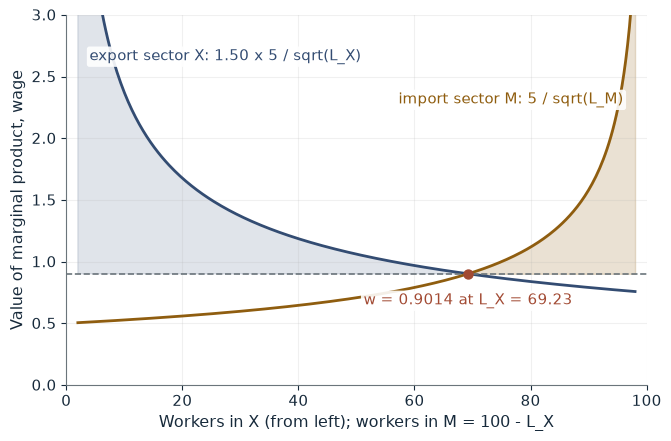

L_X                 69.23
L_M                 30.77
Wage w              0.9014
Wage change (in M)  +27.5%
Real wage in X      0.6009 (-15.0%)
Rent R_X            62.40 (+76.5%)
Rent R_M            27.74 (-21.6%)

Worked steps:
  1. L_X / L_M = 1.50 x 1.50 = 2.2500
  2. L_M = 100 / 3.2500 = 30.77; L_X = 100 - 30.77 = 69.23
  3. w = 5 / sqrt(30.77) = 0.9014
  4. Wage in X = 0.9014 / 1.50 = 0.6009
  5. R_X = 1.50 x 5 x sqrt(69.23) = 62.40; R_M = 5 x sqrt(30.77) = 27.74

Wage equality gives L_X = 1.50^2 L_M = 2.2500 L_M, so L_M = 100 / 3.2500 = 30.77 and L_X = 69.23. The wage is 5 / sqrt(30.77) = 0.9014, +27.5 percent from 0.7071; measured in X it is 0.9014 / 1.50 = 0.6009. R_X = 1.50 x 5 x sqrt(69.23) = 62.40 and R_M = 5 x sqrt(30.77) = 27.74, against 35.36 each at the start. Workers gain in terms of M but lose in terms of X; the X-specific factor clearly gains and the M-specific factor clearly loses.


In [6]:
show(specific_picture(px=1.5))

Change one input, `px`, and hold the others at the book's values:

In [7]:
sweep(specific_picture, 'px', [1.0, 1.25, 1.5, 2.0], {}, ['Wage w', 'Real wage in X', 'Rent R_X', 'Rent R_M'])

px | Wage w | Real wage in X | Rent R_X | Rent R_M
1.0 | 0.7071 | 0.7071 (0.0%) | 35.36 (0.0%) | 35.36 (0.0%)
1.25 | 0.8004 | 0.6403 (-9.4%) | 48.80 (+38.0%) | 31.23 (-11.7%)
1.5 | 0.9014 | 0.6009 (-15.0%) | 62.40 (+76.5%) | 27.74 (-21.6%)
2.0 | 1.1180 | 0.5590 (-20.9%) | 89.44 (+153.0%) | 22.36 (-36.8%)


The wage rises 27.5 percent to 0.9014 but falls 15.0 percent in terms of X. The X-specific rent rises 76.5 percent to 62.40 and the M-specific rent falls 21.6 percent to 27.74.

## 4. Factor-price equalization theorem

With common trade prices both countries solve

$$2w+r=30,\qquad w+2r=36,$$

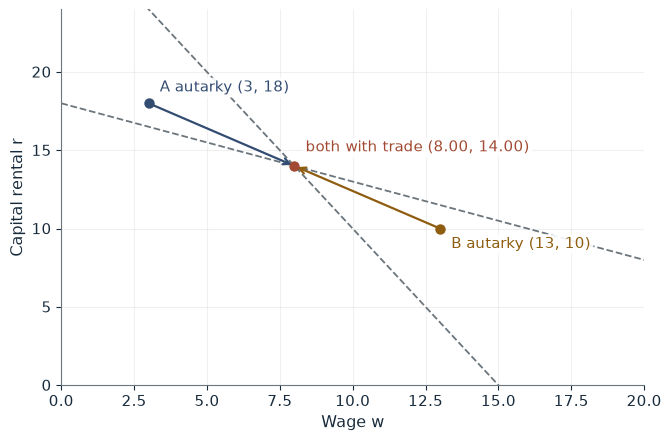

Prices in force  pC = 30, pM = 36 in both countries
Common wage      8.00
Common rental    14.00
A's wage         3 to 8.00
B's wage         13 to 8.00

Worked steps:
  1. 2w + r = 30 and w + 2r = 36
  2. 3r = 2 x 36 - 30 = 42, so r = 14.00
  3. w = 36 - 2 x 14.00 = 8.00
  4. A: (3, 18) to (8.00, 14.00); B: (13, 10) to (8.00, 14.00)

With common prices pC = 30 and pM = 36, both countries solve 2w + r = 30 and w + 2r = 36. Then 3r = 2 x 36 - 30 = 42, so r = 14.00, and w = 36 - 2 x 14.00 = 8.00. A's wage rises from 3 and its rental falls from 18; B's wage falls from 13 and its rental rises from 10. Factor prices are equal although no factor crosses the border.


In [8]:
show(fpe_picture(regime='free trade', pm=36))

Change one input, `pm`, and hold the others at the book's values:

In [9]:
sweep(fpe_picture, 'pm', [33, 36, 39], {'regime': 'free trade'}, ['Common wage', 'Common rental'])

pm | Common wage | Common rental
33 | 9.00 | 12.00
36 | 8.00 | 14.00
39 | 7.00 | 16.00


A moves from (3, 18) and B from (13, 10) to the common point (8, 14), although no factor crosses the border.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

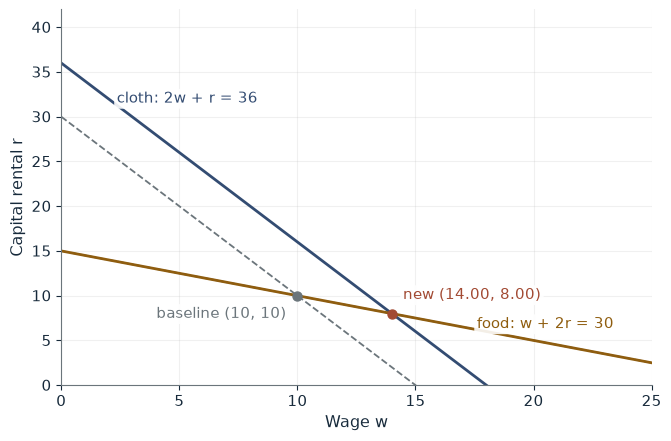

Wage w                     14.00
Rental r                   8.00
Wage change                +40.00%
Cloth price change         +20.00%
Food price change          0.00%
Real wage in cloth w/pC    0.389
Real wage in food w/pF     0.467
Real rental in cloth r/pC  0.222
Real rental in food r/pF   0.267

Worked steps:
  1. 2w + r = 36 and w + 2r = 30
  2. 3r = 2 x 30 - 36 = 24, so r = 8.00
  3. w = (36 - 8.00) / 2 = 14.00
  4. Wage change = (14.00 - 10) / 10 = +40.00%
  5. Real wage: 14.00 / 36 = 0.389 cloth, 14.00 / 30 = 0.467 food

Subtracting 2 x (w + 2r = 30) from 2w + r = 36 gives -3r = 36 - 60, so r = 8.00 and w = (36 - 8.00) / 2 = 14.00. The wage rises 40.00 percent against a cloth price change of 20.00 percent and a food price change of 0.00 percent. Starting from 10 / 30 = 0.333 of either good, the wage buys 14.00 / 36 = 0.389 cloth and 14.00 / 30 = 0.467 food; the rental buys 0.222 cloth and 0.267 food. Labor gains in terms of both goods, and capital loses in terms of both goods.


In [10]:
show(stolper_picture(pc=36, pf=30))

## Practice

**1.** At pC = 36 and pF = 30, what is capital's food purchasing power?

<details><summary>Answer</summary>

r = 8, so 8 / 30 = 0.267, down from 10 / 30 = 0.333.

</details>

**2.** With L = 360 and K = 300, why can cloth not rise by 30 with machines held at 100?

<details><summary>Answer</summary>

130 cloth and 100 machines need 130 + 200 = 330 capital units, 30 more than exist; the equilibrium is X = 140, Y = 80.

</details>

**3.** What are factor prices if pC = 30 and pM = 36?

<details><summary>Answer</summary>

3r = 2 x 36 - 30 = 42, so r = 14, and w = 36 - 28 = 8.

</details>